# Learning and Validation Curves

This notebook plots learning curves and validation curves with confidence bands and interprets the high-bias, high-variance and good-fit scenarios by comparing under- and over-regularised models.

## Import Required Libraries

Import the dataset, model and diagnostic-curve utilities.

In [1]:
# Import the required libraries.
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.svm import SVC
from sklearn.model_selection import (
    learning_curve, validation_curve
)

# Define the course colour palette.
colors = ["#179E86", "#2580B7", "#9EBE5B",
          "#C03B26", "#44546A", "#F59B11"]
np.random.seed(42)

## Load the Dataset

Use the handwritten digits dataset, a ten-class classification problem.

In [2]:
# Load the digits dataset.
data = load_digits()
X, y = data.data, data.target
print(f"Samples: {X.shape[0]}, features: {X.shape[1]}.")
print(f"Classes: {np.unique(y)}.")

Samples: 1797, features: 64.
Classes: [0 1 2 3 4 5 6 7 8 9].


## Learning Curve

Vary the training-set size and record the training and cross-validation scores to see whether more data would help.

In [3]:
# Compute a learning curve for a moderate SVM.
sizes, train_scores, val_scores = learning_curve(
    SVC(kernel="rbf", C=10, gamma=0.001), X, y,
    train_sizes=np.linspace(0.1, 1.0, 6), cv=5,
    random_state=42
)
train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)
print(f"Final train score: {train_mean[-1]:.4f}.")
print(f"Final CV score:    {val_mean[-1]:.4f}.")

Final train score: 1.0000.
Final CV score:    0.9722.


## Plot the Learning Curve

Shade one standard deviation around each mean to show the confidence band.

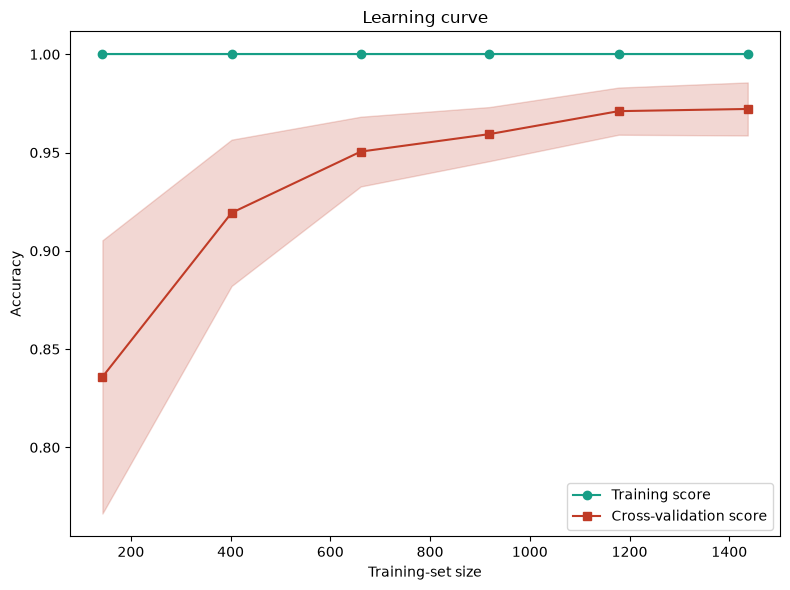

In [4]:
# Plot the learning curve with confidence bands.
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(sizes, train_mean, marker="o", color=colors[0],
        label="Training score")
ax.fill_between(sizes, train_mean - train_std,
                train_mean + train_std, color=colors[0],
                alpha=0.2)
ax.plot(sizes, val_mean, marker="s", color=colors[3],
        label="Cross-validation score")
ax.fill_between(sizes, val_mean - val_std, val_mean + val_std,
                color=colors[3], alpha=0.2)
ax.set_xlabel("Training-set size")
ax.set_ylabel("Accuracy")
ax.set_title("Learning curve")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Validation Curve

Sweep the SVM `gamma` to expose underfitting at low complexity and overfitting at high complexity.

In [5]:
# Compute a validation curve over gamma.
gammas = np.logspace(-5, 0, 6)
train_vc, val_vc = validation_curve(
    SVC(kernel="rbf", C=10), X, y,
    param_name="gamma", param_range=gammas, cv=5
)
tr_mean = train_vc.mean(axis=1)
va_mean = val_vc.mean(axis=1)
va_std = val_vc.std(axis=1)
for g, tr, va in zip(gammas, tr_mean, va_mean):
    print(f"gamma={g:.0e}: train={tr:.3f}, cv={va:.3f}.")

gamma=1e-05: train=0.980, cv=0.945.
gamma=1e-04: train=0.998, cv=0.960.
gamma=1e-03: train=1.000, cv=0.972.
gamma=1e-02: train=1.000, cv=0.707.
gamma=1e-01: train=1.000, cv=0.102.
gamma=1e+00: train=1.000, cv=0.139.


## Plot the Validation Curve

A large train-vs-validation gap on the right signals high variance (overfitting); low scores on both sides signal high bias.

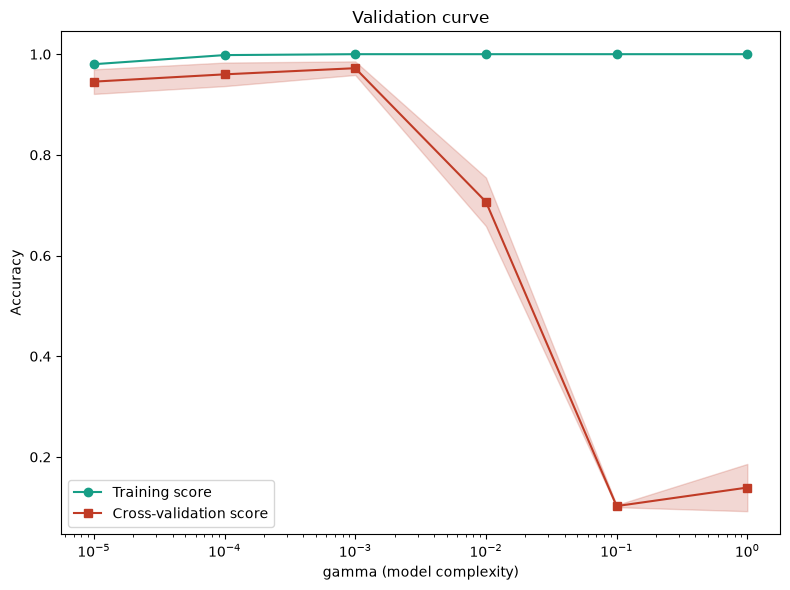

In [6]:
# Plot the validation curve over gamma.
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(gammas, tr_mean, marker="o", color=colors[0],
        label="Training score")
ax.plot(gammas, va_mean, marker="s", color=colors[3],
        label="Cross-validation score")
ax.fill_between(gammas, va_mean - va_std, va_mean + va_std,
                color=colors[3], alpha=0.2)
ax.set_xscale("log")
ax.set_xlabel("gamma (model complexity)")
ax.set_ylabel("Accuracy")
ax.set_title("Validation curve")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

## Under- vs Over-Regularised Learning Curves

Plot the learning curves of an over-regularised model (high bias) and an under-regularised model (high variance) side by side.

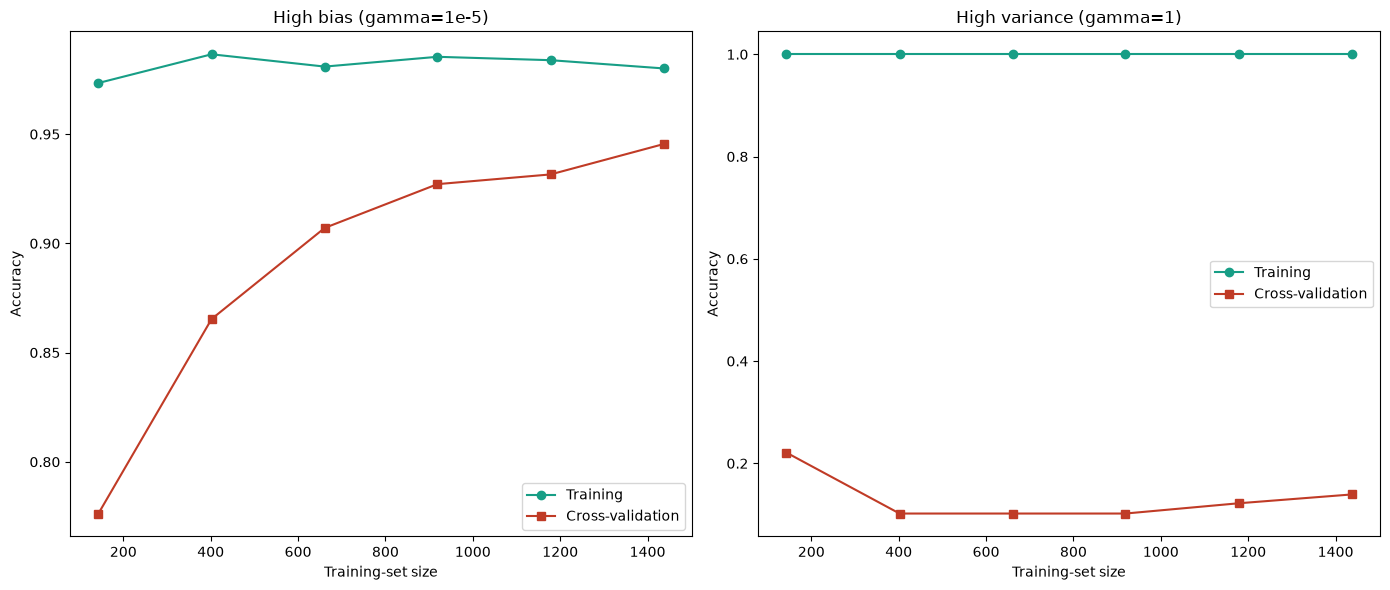

In [7]:
# Compare high-bias and high-variance learning curves.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
settings = [
    ("High bias (gamma=1e-5)", 1e-5),
    ("High variance (gamma=1)", 1.0),
]
for ax, (title, gamma) in zip(axes, settings):
    s, tr, va = learning_curve(
        SVC(kernel="rbf", C=10, gamma=gamma), X, y,
        train_sizes=np.linspace(0.1, 1.0, 6), cv=5,
        random_state=42
    )
    ax.plot(s, tr.mean(axis=1), marker="o", color=colors[0],
            label="Training")
    ax.plot(s, va.mean(axis=1), marker="s", color=colors[3],
            label="Cross-validation")
    ax.set_title(title)
    ax.set_xlabel("Training-set size")
    ax.set_ylabel("Accuracy")
    ax.legend(loc="best")
plt.tight_layout()
plt.show()

## Summary

- **Learning curve**: plots score against training-set size; converged low scores mean high bias, a persistent gap means high variance.
- **Validation curve**: plots score against a complexity knob to locate the underfitting-overfitting sweet spot.
- **High bias**: both curves are low and close; more data alone will not help, add capacity or features.
- **High variance**: training far exceeds validation; more data or stronger regularisation closes the gap.